# 05 — Read the order book: price versus liquidity

**Question:** What would a particular trade size cost at an observed book?

**By the end:** read ladders and cumulative depth, compute an exact displayed-book
VWAP, recognize partial depth, and distinguish hypothetical execution arithmetic
from actual fills. **Time:** 30–40 minutes.

**Inputs:** reconstructed outcome books with their original seeds and socket
epochs. Fees, order constraints and queue position are not invented.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    plot_style,
    walk_book,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Choose an eligible recorded moment

We select the eligible point closest to the window's midpoint, not the point with
the most attractive profit. You can later choose another grid time explicitly.
The ladder is reconstructed at that same local receipt time.

In [3]:
study = BookStudy(sample)
grid = study.grid()
iid = next(i for i, label in sample.labels.items() if str(label).lower() == "up")
up = grid[grid.instrument_id == iid].copy()
candidates = up[up.analysis_eligible]
assert not candidates.empty, "No eligible Up book is available in this sample."
target = pd.Timestamp((sample.start + sample.end) // 2, tz="UTC")
chosen = candidates.loc[(candidates.time - target).abs().idxmin()]
book = study.book_at(iid, chosen.time.value)
display(chosen[["time", "bid", "ask", "spread", "age_s", "assurance", "epoch_id"]])
bids, asks = pd.DataFrame(book["bids"]), pd.DataFrame(book["asks"])
display(bids.head(8))
display(asks.head(8))

time                                 2026-10-01 15:47:30+00:00
bid                                                       0.92
ask                                                       0.93
spread                                                    0.01
age_s                                                 0.095614
assurance                                   UNKNOWN_CONTINUITY
epoch_id     f5126c7dfc74ca7c95750b3d4ae766596bceac9bae4a1a...
Name: 150, dtype: object

,price,quantity
0,0.920000000000000000000000000000,96.730000000000000000000000000000
1,0.910000000000000000000000000000,752.530000000000000000000000000000
2,0.900000000000000000000000000000,349.000000000000000000000000000000
3,0.890000000000000000000000000000,690.510000000000000000000000000000
4,0.880000000000000000000000000000,556.100000000000000000000000000000
5,0.870000000000000000000000000000,728.680000000000000000000000000000
6,0.860000000000000000000000000000,516.910000000000000000000000000000
7,0.850000000000000000000000000000,587.560000000000000000000000000000


,price,quantity
0,0.930000000000000000000000000000,1677.270000000000000000000000000000
1,0.940000000000000000000000000000,874.100000000000000000000000000000
2,0.950000000000000000000000000000,1728.700000000000000000000000000000
3,0.960000000000000000000000000000,1981.750000000000000000000000000000
4,0.970000000000000000000000000000,1322.250000000000000000000000000000
5,0.980000000000000000000000000000,5655.250000000000000000000000000000
6,0.990000000000000000000000000000,8788.460000000000000000000000000000


## 2. Standing orders and cumulative depth

Bid quantities are displayed buying interest; ask quantities are displayed selling
interest. A best ask is only the first level. To buy more, you may need higher ask
levels. Only recorded displayed depth is known; hidden interest and future orders
are outside the calculation.

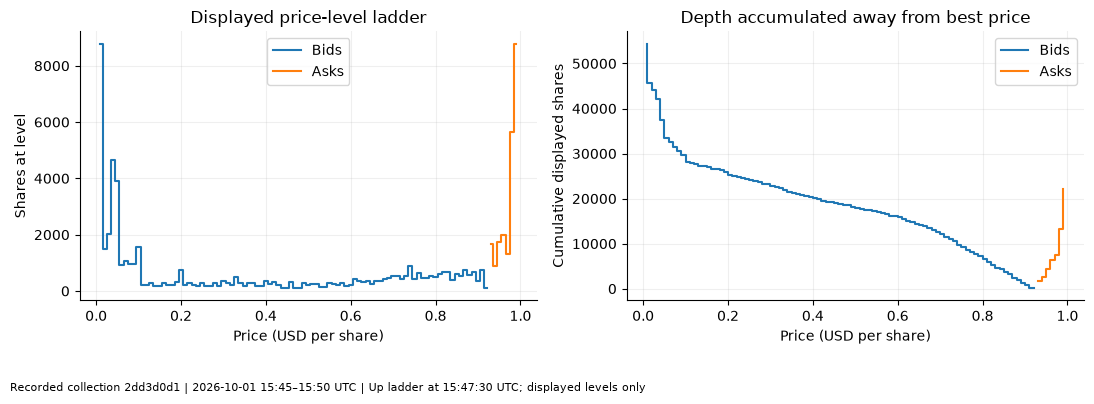

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for frame, label in [(bids, "Bids"), (asks, "Asks")]:
    px = frame.price.map(float).to_numpy()
    qty = frame.quantity.map(float).to_numpy()
    axes[0].step(px, qty, where="mid", label=label)
    axes[1].step(px, np.cumsum(qty), where="post", label=label)
axes[0].set(
    title="Displayed price-level ladder", xlabel="Price (USD per share)", ylabel="Shares at level"
)
axes[1].set(
    title="Depth accumulated away from best price",
    xlabel="Price (USD per share)",
    ylabel="Cumulative displayed shares",
)
for ax in axes:
    ax.legend()
finish_plot(fig, sample, f"Up ladder at {chosen.time:%H:%M:%S} UTC; displayed levels only")

## 3. Walk the asks using exact arithmetic

For each level, take the smaller of the remaining requested shares and displayed
shares. Sum `price × quantity`. Divide cash by filled shares to obtain VWAP.
If the recorded book runs out, the result is partial; a partial VWAP does not price
the remaining order. No rounding to a trading tick or minimum order is imposed here.

,requested_shares,displayed_fill_shares,unfilled_shares,cash_before_fees,vwap,complete,slippage_vs_best_ask
0,10,10,0,9.300000000000000000000000000000,0.930000000000000000000000000000,True,0E-30
1,50,50,0,46.500000000000000000000000000000,0.930000000000000000000000000000,True,0E-30
2,100,100,0,93.000000000000000000000000000000,0.930000000000000000000000000000,True,0E-30
3,250,250,0,232.500000000000000000000000000000,0.930000000000000000000000000000,True,0E-30
4,500,500,0,465.000000000000000000000000000000,0.930000000000000000000000000000,True,0E-30
5,1000,1000,0,930.000000000000000000000000000000,0.930000000000000000000000000000,True,0E-30


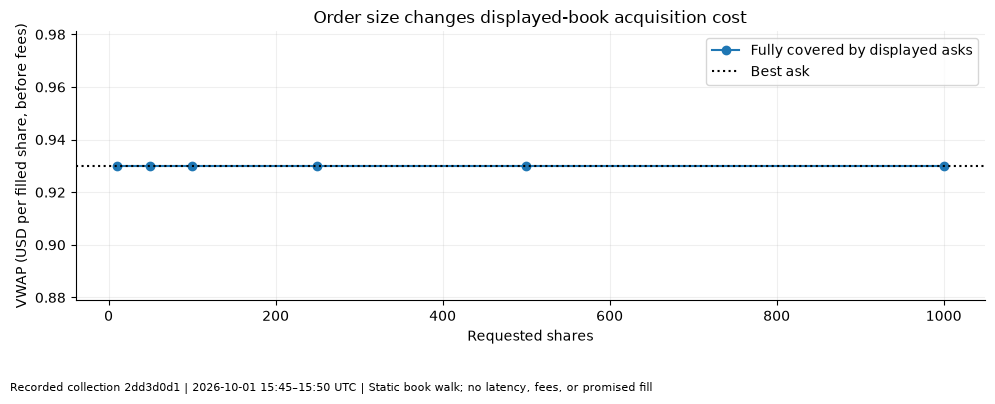

In [4]:
sizes = [10, 50, 100, 250, 500, 1000]
costs = pd.DataFrame([walk_book(book, n) for n in sizes])
best_ask = book["asks"][0]["price"]
costs["slippage_vs_best_ask"] = costs.vwap.map(lambda p: p - best_ask if p is not None else None)
display(costs)
fig, ax = plt.subplots()
complete = costs[costs.complete]
if not complete.empty:
    ax.plot(
        complete.requested_shares.map(float),
        complete.vwap.map(float),
        marker="o",
        label="Fully covered by displayed asks",
    )
partial = costs[~costs.complete & costs.vwap.notna()]
if not partial.empty:
    ax.scatter(
        partial.requested_shares.map(float),
        partial.vwap.map(float),
        marker="x",
        label="Partial displayed fill only",
    )
ax.axhline(float(best_ask), color="black", linestyle=":", label="Best ask")
ax.set(
    title="Order size changes displayed-book acquisition cost",
    xlabel="Requested shares",
    ylabel="VWAP (USD per filled share, before fees)",
)
ax.legend()
finish_plot(fig, sample, "Static book walk; no latency, fees, or promised fill")

## 4. Entry and exit both consume liquidity

Buying at asks and immediately selling into bids costs the spread and possibly
additional depth slippage. This thought experiment uses the same unchanged book;
it ignores our own impact, latency and fees, so it is an arithmetic illustration,
not an execution simulator.

In [5]:
roundtrips = []
for n in [10, 50, 100]:
    purchase, sale = walk_book(book, n, "buy"), walk_book(book, n, "sell")
    roundtrips.append(
        {
            "shares": n,
            "both_sides_have_displayed_depth": purchase["complete"] and sale["complete"],
            "static_roundtrip_cash_USD": sale["cash_before_fees"] - purchase["cash_before_fees"]
            if purchase["complete"] and sale["complete"]
            else None,
        }
    )
display(pd.DataFrame(roundtrips))

,shares,both_sides_have_displayed_depth,static_roundtrip_cash_USD
0,10,True,-0.1000000000000000000000000000
1,50,True,-0.5000000000000000000000000000
2,100,True,-1.032700000000000000000000000


## 5. Liquidity changes during the window

The spread and best-level size can move independently. A narrow spread with tiny
quantity is different from the same spread with ample displayed shares. Masked
intervals remain visible rather than suggesting continuous executable liquidity.

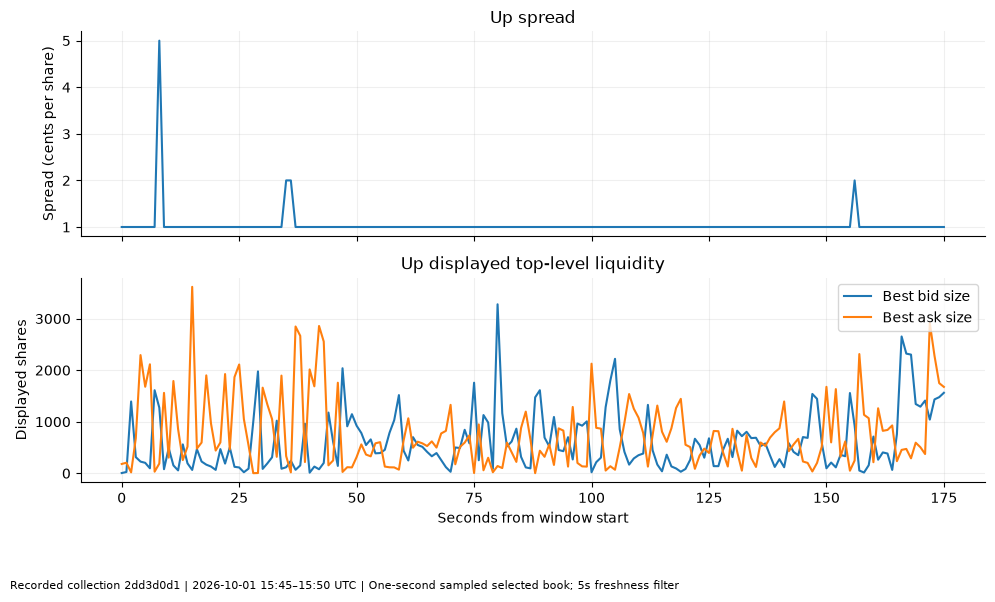

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = (up.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
axes[0].plot(x, up.spread * 100)
axes[0].set(title="Up spread", ylabel="Spread (cents per share)")
axes[1].plot(x, up.bid_quantity, label="Best bid size")
axes[1].plot(x, up.ask_quantity, label="Best ask size")
axes[1].set(
    title="Up displayed top-level liquidity",
    xlabel="Seconds from window start",
    ylabel="Displayed shares",
)
axes[1].legend()
finish_plot(fig, sample, "One-second sampled selected book; 5s freshness filter")

## Exercise — make the order larger

Try 5,000 and 50,000 shares. Does the book cover the entire quantity? What does
the VWAP mean when `complete` is false?

**Suggested answer:** it is the average price of only the displayed quantity that
could be matched in this static calculation. The remaining shares have no inferred
price or fill. Do not extrapolate the last observed level into unlimited liquidity.

**Research use:** executable-size curves constrain any $3 expected-edge sizing
idea. **What remains unknown:** actual fills after order delay, historical fees,
tick/minimum-size compliance, private queue position and replenishment.

Next: [06 — Order flow](06_order_flow_and_book_dynamics.ipynb).